In [1]:
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.init as init
import matplotlib.pyplot as plt

from torchvision import datasets, transforms
from torch.utils.data import random_split, DataLoader

# Configuration

In [2]:
SCHEDULER_TYPE = 'step' # options: step | exp | cosine | plateau

# GPU Support

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

Device: cuda


# ETL
## Extract Data

In [4]:
transform = transforms.ToTensor()

dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 38.9MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.09MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 9.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.77MB/s]


## Train / Validation Data

In [5]:
train_size = int(0.8 * len(dataset))
train_size

48000

In [6]:
val_size = len(dataset) - train_size
val_size

12000

In [7]:
train_data, val_data = random_split(dataset, [train_size, val_size])

## Mini-Batch (1024)

In [8]:
train_loader = DataLoader(train_data, batch_size=1024, shuffle=True,num_workers=2,pin_memory=True)
val_loader = DataLoader(val_data,batch_size=1024,num_workers=2,pin_memory=True)

## Test Data

In [9]:
test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [10]:
test_loader = DataLoader(test_data, batch_size=1024,num_workers=2,pin_memory=True)

# Model

image:
- 28px x 28px
- 1 channel (grayscale)
- => 28x28x1 = 784 neuron

> Model


* Layers = Input + Hidden + Hidden + Output
* BatchNorm
* ReLU (activation function)
* Dropout (ovrfitting) (30%)

In [11]:
model = nn.Sequential(
    # Input Layer 784
    nn.Flatten(),

    # Hidden Layer 1
    nn.Linear(784, 512, bias=False),
    nn.BatchNorm1d(512),
    nn.ReLU(),
    nn.Dropout(0.1),

    # Hidden Layer 2
    nn.Linear(512, 256, bias=False),
    nn.BatchNorm1d(256),
    nn.ReLU(),
    nn.Dropout(0.1),

    # Output Layer
    nn.Linear(256,10)
)

In [12]:
if torch.cuda.device_count() > 1:
    print("DataParallel GPU")
    model = nn.DataParallel(model)
    
model = model.to(device) # GPU / CPU

DataParallel GPU


# Weight Initialization

In [13]:
for layer in model.modules():
    if isinstance(layer, nn.Linear):
        init.kaiming_uniform_(layer.weight, nonlinearity='relu')
        if layer.bias is not None:
            nn.init.zeros_(layer.bias)

# Training Setup

- Optimizer = Adam
- Learning Rate = 0.001
- Criterion (Loss function) = Cross Entropy (Multi-Class Classification)

In [14]:
optimizer = optim.Adam(model.parameters(), lr=0.008)
criterion = nn.CrossEntropyLoss()

# Scheduler Setup

In [15]:
if SCHEDULER_TYPE == 'step':
    scheduler = optim.lr_scheduler.StepLR(optimizer,step_size=5,gamma=0.5) # lr = lr * 0.5
elif SCHEDULER_TYPE == 'exp':
    scheduler = optim.lr_scheduler.ExponentialLR(optimizer, gamma=0.9) # lr = lr * 0.9
elif SCHEDULER_TYPE == 'cosine':
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=20)
elif SCHEDULER_TYPE == 'plateau':
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(optimizer,mode='min',factor=0.1,patience=1) # lr = lr * 0.1

# Early Stopping

In [16]:
best_val_loss = float('inf')
patience = 5
counter = 0

best_model_state = None

# Tracking

In [17]:
train_losses = []
val_losses = []
lrs = []

# Training Loop

In [18]:
for epoch in range(100):

    # Train
    model.train()
    train_loss = 0

    for images, labels in train_loader:

        images = images.to(device) # GPU/CPU
        labels = labels.to(device) # GPU/CPU
        
        outputs = model(images)
        loss = criterion(outputs, labels)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    train_loss /= len(train_loader)

    # Validation
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device) # GPU/CPU
            labels = labels.to(device) # GPU/CPU
            
            outputs = model(images)
            loss = criterion(outputs, labels)

            val_loss += loss.item()

        val_loss /= len(val_loader)

    current_lr = optimizer.param_groups[0]['lr']

    # saving metrics
    train_losses.append(train_loss)
    val_losses.append(val_loss)
    lrs.append(current_lr)
    
    print(f"Epoch {epoch} => train loss = {train_loss:.4f}, val loss = {val_loss:.4f}, lr = {current_lr:.6f}")

    # Scheduler Step
    if SCHEDULER_TYPE == 'plateau':
        scheduler.step(val_loss)
    else:
        scheduler.step()
    
    # Early Stopping
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        counter = 0
        best_model_state = model.state_dict()
    else:
        counter += 1

    if counter >= patience:
        print("Early Stopping Triggered")
        print(f"Epoch {epoch} => train loss = {train_loss:.4f}, val loss = {val_loss:.4f}")
        break

/usr/local/lib/python3.12/dist-packages/torch/nn/modules/linear.py:134: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at /pytorch/aten/src/ATen/cuda/CublasHandlePool.cpp:330.)
  return F.linear(input, self.weight, self.bias)


Epoch 0 => train loss = 0.2911, val loss = 0.1430, lr = 0.008000
Epoch 1 => train loss = 0.0966, val loss = 0.1030, lr = 0.008000
Epoch 2 => train loss = 0.0616, val loss = 0.0912, lr = 0.008000
Epoch 3 => train loss = 0.0473, val loss = 0.0951, lr = 0.008000
Epoch 4 => train loss = 0.0360, val loss = 0.0990, lr = 0.008000
Epoch 5 => train loss = 0.0208, val loss = 0.0728, lr = 0.004000
Epoch 6 => train loss = 0.0114, val loss = 0.0762, lr = 0.004000
Epoch 7 => train loss = 0.0086, val loss = 0.0770, lr = 0.004000
Epoch 8 => train loss = 0.0086, val loss = 0.0742, lr = 0.004000
Epoch 9 => train loss = 0.0076, val loss = 0.0789, lr = 0.004000
Epoch 10 => train loss = 0.0054, val loss = 0.0736, lr = 0.002000
Early Stopping Triggered
Epoch 10 => train loss = 0.0054, val loss = 0.0736


# Load Best Model

In [19]:
if best_model_state is not None:
    model.load_state_dict(best_model_state)

# Test (Accuracy)

In [20]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device) # GPU/CPU
        labels = labels.to(device) # GPU/CPU
        
        outputs = model(images)
        value, predicted = torch.max(outputs,1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()


accuracy = correct / total

print(f"Fianl Accuracy: {accuracy:.4f}")

Fianl Accuracy: 0.9826


# Plot

## Learning Curve

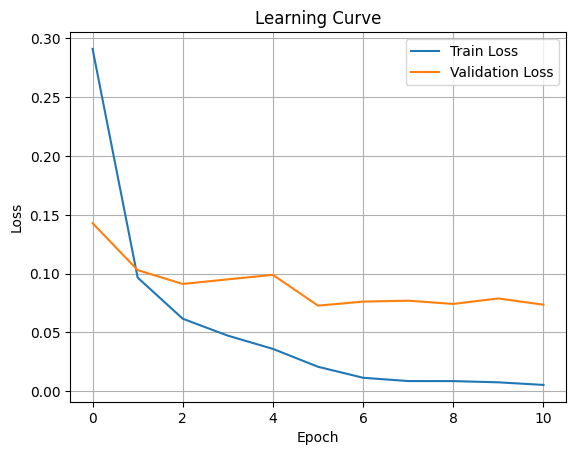

In [21]:
plt.figure()
plt.plot(train_losses, label="Train Loss")
plt.plot(val_losses, label = "Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Learning Curve")
plt.legend()
plt.grid()
plt.show()

## Learning Rate

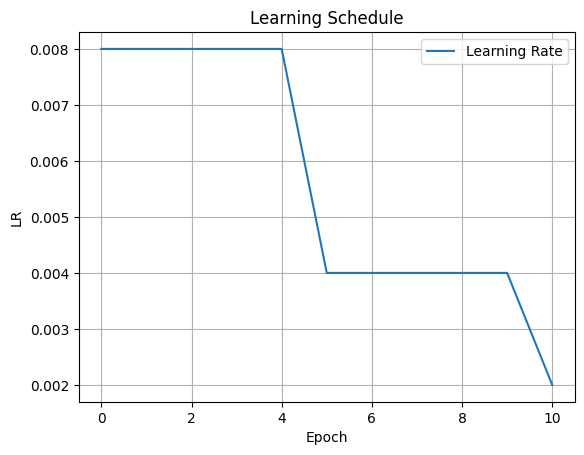

In [22]:
plt.figure()
plt.plot(lrs, label="Learning Rate")
plt.xlabel("Epoch")
plt.ylabel("LR")
plt.title("Learning Schedule")
plt.legend()
plt.grid()
plt.show()

# Saving Model

In [23]:
torch.save(model.state_dict(),"best_model.pth")
print("Model Saved")

Model Saved
